# **Les tests d'hypothèses**

## **Contexte:**

Après avoir découvert les *statistiques descriptives*, qui permettent de **résumer et observer les données**, on peut aller plus loin avec les *tests d’hypothèses*. Ceux-ci répondent à une question clé : **l’effet ou la différence observée est-il réel, ou simplement dû au hasard ?** 

Pour le comprendre, il faut distinguer la *population*, c’est-à-dire l’ensemble complet des individus ou éléments que l’on voudrait étudier, et *l’échantillon*, qui en est un sous-ensemble accessible et sur lequel on fait des mesures. Comme il est souvent impossible d’analyser toute la population, les tests d’hypothèses permettent, à partir d’un échantillon, d’estimer si les résultats peuvent être généralisés à l’ensemble. En pratique, on compare les données observées à une situation de référence (l’hypothèse nulle) et on utilise les probabilités pour juger si l’écart observé est suffisamment significatif pour être pris au sérieux. Ainsi, on passe de la simple description des données à une véritable aide à la décision.

## Détails pratiques

Temps estimés :
- Parties 2/3 lois et théorèmes : 1/2 journée
- 4.2.1 > 4.2.3 : 1 journée
- 4.2.4 : 1/2 journée
- 5 enquête bonheur : 1/2 journée

Signification des émoticones :
- 🌞 : documentations importantes
- 🌚 : en complément
- (vide) : à vous de voir

# Import des librairies

In [1]:
# manipulation de dataframes
import pandas as pd 

🌞 https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf

In [2]:
# réalisation des graphiques
import matplotlib.pyplot as plt

In [3]:
# réalisation des graphiques
import seaborn as sns

In [4]:
# tests d'hypothèses
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest

In [5]:
# calculs scientifiques
import numpy as np

In [6]:
# fonction de répartition empirique
from statsmodels.distributions.empirical_distribution import ECDF

In [7]:
import plotly.express as px

In [8]:
pd.options.plotting.backend = "plotly"

# Quelques lois intéressantes à connaitre en statistiques

Nous notons ici différentes lois intéressantes en statistiques. L'idée ici n'est pas de les connaitre toutes dans un premier temps, mais de savoir qu'elles existent. L'intérêt des lois pour nous aujourd'hui est de pouvoir comparer la distribution de nos variables à ces lois.

## Modèles discrets

Les variables aléatoires <b/>discrètes</b> prennent <b/>un nombre fini ou dénombrable</b> de valeurs distinctes.</br>
</br>

- Loi Uniforme : https://fr.wikipedia.org/wiki/Loi_uniforme_discr%C3%A8te</br>
La probabilité que la variable aléatoire X prenne chacune des valeurs de son support est identique, autrement dit, il y a équiprobabilité.</br>
</br>

- Loi de Bernouilli : https://fr.wikipedia.org/wiki/Loi_de_Bernoulli</br>
On considère une épreuve aléatoire à deux issues. L'une est considérée comme le succès, l'autre comme l'échec. C'est ce que l'on appelle une épreuve de Bernoulli.</br>
Par exemple, on lance un dé. On obtient 6, c'est le succès. On n'obtient pas 6, c'est l'échec.</br>
</br>

- Loi Binomiale : https://fr.wikipedia.org/wiki/Loi_binomiale</br>
On considère à nouveau une épreuve de Bernoulli : épreuve aléatoire à deux issues. L'une est considérée comme le succès, l'autre comme l'échec. Cette fois, on répète cette épreuve de manière identique et indépendante pour obtenir ce que l'on appelle un schéma de Bernoulli. </br>
Exemple : on reprend le lancer de dé. On lance ce dé un certain nombre de fois. Disons n fois, n étant un entier naturel non nul. On désigne par X la VAD qui compte le nombre de succès, c'est-à-dire le nombre de fois où on a obtenu un 6.

## Modèles continus

Les variables aléatoires <b/>continues</b> peuvent prendre <b/>une infinité de valeurs</b> dans un intervalle donné.</br>

- Loi Uniforme : https://fr.wikipedia.org/wiki/Loi_uniforme_continue</br>
Toutes les valeurs possibles d'un intervalle donné ont la même probabilité de se produire.</br>

- Loi Normale : https://fr.wikipedia.org/wiki/Loi_normale</br>
C'est une loi symétrique en forme de cloche, où la majorité des valeurs se concentrent autour de la moyenne, avec une décroissance des probabilités à mesure que l'on s'éloigne de celle-ci.</br>

- Loi de Student : https://fr.wikipedia.org/wiki/Loi_de_Student</br>
Cette loi est utilisée pour estimer les moyennes de populations normalement distribuées lorsqu'on a un petit échantillon, caractérisée par des queues plus épaisses que celles de la loi normale.</br>

- Loi du Chi-Deux : https://fr.wikipedia.org/wiki/Loi_du_%CF%87%C2%B2</br>
On l'utilise pour tester l'adéquation entre des données observées et des données théoriques. Elle est souvent appliquée dans les tests d'indépendance et les tests d'ajustement.

🌚 https://maths.cnam.fr/IMG/pdf/Cours5_Graphiques_Lois_usuelles.pdf

## Focus sur la Loi Normale : la plus intéressante pour nous aujourd'hui

Générons de manière aléatoire une variable température (de moyenne 15°C et d'écart-type 3°C par exemple) qui suivrait une loi Normale afin de se rendre compte de la forme qu'elle a :

https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html

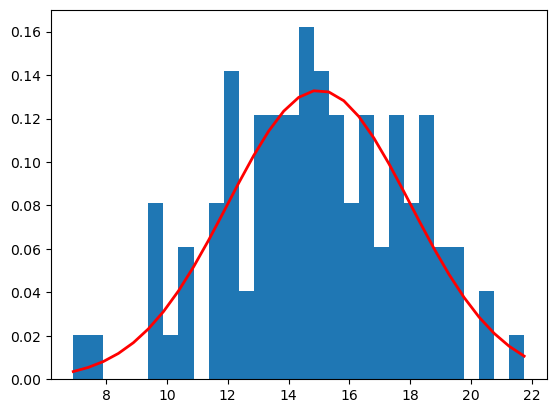

In [9]:

mu, sigma = 15, 3
temperatures = np.random.normal(mu, sigma, size=100)

count, bins, ignored = plt.hist(temperatures, 30, density=True)
plt.plot(bins, 1/(sigma * np.sqrt(2 * np.pi)) *
               np.exp( - (bins - mu)**2 / (2 * sigma**2) ),
         linewidth=2, color='r')
plt.show()

Que se passe-t-il si on joue avec la size ?

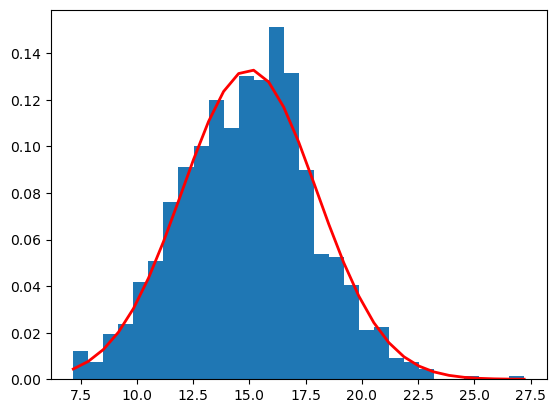

In [10]:
temperatures = np.random.normal(mu, sigma, size=1000)
count, bins, ignored = plt.hist(temperatures, 30, density=True)
plt.plot(bins, 1/(sigma * np.sqrt(2 * np.pi)) *
               np.exp( - (bins - mu)**2 / (2 * sigma**2) ),
         linewidth=2, color='r')
plt.show()

# Quelques théorèmes fondamentaux à connaitre en statistiques

## La loi des grands nombres

Ressources :</br>
- 🌞 https://www.youtube.com/watch?v=HRnYFpdR8WM
- https://fr.wikipedia.org/wiki/Loi_des_grands_nombres
- 🌚 https://www.datacamp.com/fr/tutorial/law-of-large-numbers

**En résumé** : elle signifie que la moyenne empirique (calculée sur les valeurs d’un échantillon), converge vers l’espérance (moyenne de la population globale réelle : extrapolation) lorsque la taille de l’échantillon tend vers l’infini.

## Le Théorème Central Limite (TCL)

Ressources :</br>
- 🌞 https://www.youtube.com/watch?v=4dhm2QAA2x4
- 🌞 https://www.youtube.com/watch?v=YAlJCEDH2uY
- https://fr.wikipedia.org/wiki/Th%C3%A9or%C3%A8me_central_limite
- 🌚 https://www.datacamp.com/fr/tutorial/central-limit-theorem
- 🌚 Afin de bien saisir la notion, vous pouvez jouer avec ce simulateur : https://im2ag-shiny.univ-grenoble-alpes.fr/fcorset/TCL/
- 🌚 Un autre petit jeu à explorer pour comprendre : https://probastat.dyndoc.fr/statinf/aep

**En résumé** : il établit la convergence en loi de la somme d'une suite de variables aléatoires vers la loi normale.

# Sujet 1 : Les passagers du Titanic

🌞 Source : https://www.kaggle.com/datasets/vinicius150987/titanic3

## A quoi ressemblent nos données ?

### Importons le jeu de données

In [11]:
df = pd.read_csv('titanic_complet.csv', sep=';')
df

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1.0,1.0,"Allen, Miss. Elisabeth Walton",female,29,0.0,0.0,24160,"211,3375",B5,S,2,NaN,"St Louis, MO"
1,1.0,1.0,"Allison, Master. Hudson Trevor",male,"0,9167",1.0,2.0,113781,"151,5500",C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1.0,0.0,"Allison, Miss. Helen Loraine",female,2,1.0,2.0,113781,"151,5500",C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1.0,0.0,"Allison, Mr. Hudson Joshua Creighton",male,30,1.0,2.0,113781,"151,5500",C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1.0,0.0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1.0,2.0,113781,"151,5500",C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3.0,0.0,"Zabour, Miss. Thamine",female,NaN,1.0,0.0,2665,"14,4542",NaN,C,NaN,NaN,NaN
1306,3.0,0.0,"Zakarian, Mr. Mapriededer",male,"26,5",0.0,0.0,2656,"7,2250",NaN,C,NaN,304.0,NaN
1307,3.0,0.0,"Zakarian, Mr. Ortin",male,27,0.0,0.0,2670,"7,2250",NaN,C,NaN,NaN,NaN
1308,3.0,0.0,"Zimmerman, Mr. Leo",male,29,0.0,0.0,315082,"7,8750",NaN,S,NaN,NaN,NaN


In [12]:
# supprimer les lignes / colonnes vide
df.dropna(axis=0,how='all',inplace=True)
df.dropna(axis=1,how='all',inplace=True)
df

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1.0,1.0,"Allen, Miss. Elisabeth Walton",female,29,0.0,0.0,24160,"211,3375",B5,S,2,NaN,"St Louis, MO"
1,1.0,1.0,"Allison, Master. Hudson Trevor",male,"0,9167",1.0,2.0,113781,"151,5500",C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1.0,0.0,"Allison, Miss. Helen Loraine",female,2,1.0,2.0,113781,"151,5500",C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1.0,0.0,"Allison, Mr. Hudson Joshua Creighton",male,30,1.0,2.0,113781,"151,5500",C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1.0,0.0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1.0,2.0,113781,"151,5500",C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,3.0,0.0,"Zabour, Miss. Hileni",female,"14,5",1.0,0.0,2665,"14,4542",NaN,C,NaN,328.0,NaN
1305,3.0,0.0,"Zabour, Miss. Thamine",female,NaN,1.0,0.0,2665,"14,4542",NaN,C,NaN,NaN,NaN
1306,3.0,0.0,"Zakarian, Mr. Mapriededer",male,"26,5",0.0,0.0,2656,"7,2250",NaN,C,NaN,304.0,NaN
1307,3.0,0.0,"Zakarian, Mr. Ortin",male,27,0.0,0.0,2670,"7,2250",NaN,C,NaN,NaN,NaN


In [13]:
df['age'] = df['age'].str.replace(',','.').astype(float)
df['fare'] = df['fare'].str.replace(',','.').astype(float)
df


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1.0,1.0,"Allen, Miss. Elisabeth Walton",female,29.0000,0.0,0.0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1.0,1.0,"Allison, Master. Hudson Trevor",male,0.9167,1.0,2.0,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1.0,0.0,"Allison, Miss. Helen Loraine",female,2.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1.0,0.0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1.0,0.0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,3.0,0.0,"Zabour, Miss. Hileni",female,14.5000,1.0,0.0,2665,14.4542,NaN,C,NaN,328.0,NaN
1305,3.0,0.0,"Zabour, Miss. Thamine",female,NaN,1.0,0.0,2665,14.4542,NaN,C,NaN,NaN,NaN
1306,3.0,0.0,"Zakarian, Mr. Mapriededer",male,26.5000,0.0,0.0,2656,7.2250,NaN,C,NaN,304.0,NaN
1307,3.0,0.0,"Zakarian, Mr. Ortin",male,27.0000,0.0,0.0,2670,7.2250,NaN,C,NaN,NaN,NaN


### Combien y a-t-il de personnes sur le paquebot ?

In [14]:
df['name'].nunique()

1307

### Combien d'informations a-t-on sur ces personnes ?

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   float64
 1   survived   1309 non-null   float64
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   float64
 6   parch      1309 non-null   float64
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(7), object(7)
memory usage: 153.4+ KB


### Regardons les premières lignes de nos données afin de se faire une idée

In [16]:
df.head(5)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1.0,1.0,"Allen, Miss. Elisabeth Walton",female,29.0000,0.0,0.0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1.0,1.0,"Allison, Master. Hudson Trevor",male,0.9167,1.0,2.0,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1.0,0.0,"Allison, Miss. Helen Loraine",female,2.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1.0,0.0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1.0,0.0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


### Réalisons un résumé statistique afin d'avoir une idée des chiffres globaux

In [17]:
df.describe()

,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


## Analyse univariée : quelles informations pourraient être intéressantes à regarder par variable ?

### Regardons les variables qualitatives

#### Quelles sont les variables qualitatives ?

In [18]:
df.select_dtypes(include='object').columns  

Index(['name', 'sex', 'ticket', 'cabin', 'embarked', 'boat', 'home.dest'], dtype='object')

#### Quelle est la part d'hommes et de femmes ?

Montrons la répartition des effectifs :

In [19]:
prop = df.groupby('sex').size() 
prop

sex
female    466
male      843
dtype: int64

Montrons la répartition en fréquences :

https://fr.wikipedia.org/wiki/Fr%C3%A9quence_(statistiques)

In [20]:
rep = round(df.groupby('sex').size() / len(df) * 100,2)
rep

sex
female    35.6
male      64.4
dtype: float64

#### Représentons ça sous forme de graphiques afin que ce soit plus visuel

Diagramme en barres en effectifs :

In [21]:
prop.plot(kind='bar')

Diagramme en barres en proportion :

In [22]:
rep.plot(kind='bar')

#### Continuez d'explorer ce qui vous semble intéressant !

In [23]:
fig = px.pie(rep, names=rep.index, values=rep.values, title='Répartition par sexe')
fig.update_traces(textinfo='percent+label')
fig.show()

### Regardons les variables quantitatives

#### Quelles sont les variables quantitatives ?

In [24]:
df.select_dtypes(include='float').columns  

Index(['pclass', 'survived', 'age', 'sibsp', 'parch', 'fare', 'body'], dtype='object')

#### Comment est représenté l'âge des voyageurs ?

Regardons le résumé statistiques :

In [25]:
df['age'].describe()

count    1046.000000
mean       29.881135
std        14.413500
min         0.166700
25%        21.000000
50%        28.000000
75%        39.000000
max        80.000000
Name: age, dtype: float64

#### Comment peut-on regarder la répartition de l'âge sous forme de graphique ?

Regardons un diagramme en barre des effectifs / histogramme

In [26]:
# Découpe automatique en intervalles de largeur égale
intervalles = pd.cut(df['age'], bins=8)  # 8 intervalles automatiques

# Comptage par intervalle

age = intervalles.value_counts().sort_index()
age.index = age.index.astype(str)
# Bar plot
age.plot(kind='bar')

Regardons le boxplot :

https://fr.wikipedia.org/wiki/Bo%C3%AEte_%C3%A0_moustaches

In [27]:
df['age'].plot(kind='box')

#### Continuez d'explorer ce qui vous semble intéressant !

In [28]:
df['age'].plot(kind='hist')

## Croisons un peu les variables !

### Quelle est la part de femmes ayant survécu ?

Regardons la table de contingence en effectifs :

In [29]:
f_survived = df.where((df['survived']==1.0) &( df['sex'] == 'female'))['name'].nunique()
f_survived

339

Regardons la table de contingence en fréquences :

In [30]:
f_survived_freq = round((f_survived / (df.where(df['sex'] == 'female')['name'].nunique()) *100),2)
f_survived_freq

72.9

### Est-ce que les survivants sont plus des femmes ?

Regardons la table de contingence en proportion en fonction des colonnes

In [31]:
m_survived = df.where((df['survived']==1.0) &( df['sex'] == 'male'))['name'].nunique()
f_survived > m_survived

True

### Est-ce que les femmes sont plus nombreuses à avoir survécu que les hommes ?

Regardons la table de contingence en proportion en fonction des lignes

In [32]:
eff = df.groupby(['sex', 'survived']).size()
eff

sex     survived
female  0.0         127
        1.0         339
male    0.0         682
        1.0         161
dtype: int64

In [33]:
freq = round(eff / len(df) * 100, 2)
freq

sex     survived
female  0.0          9.7
        1.0         25.9
male    0.0         52.1
        1.0         12.3
dtype: float64

### Observons ça en graphiques !

Réalisons un diagramme en barres en effectifs

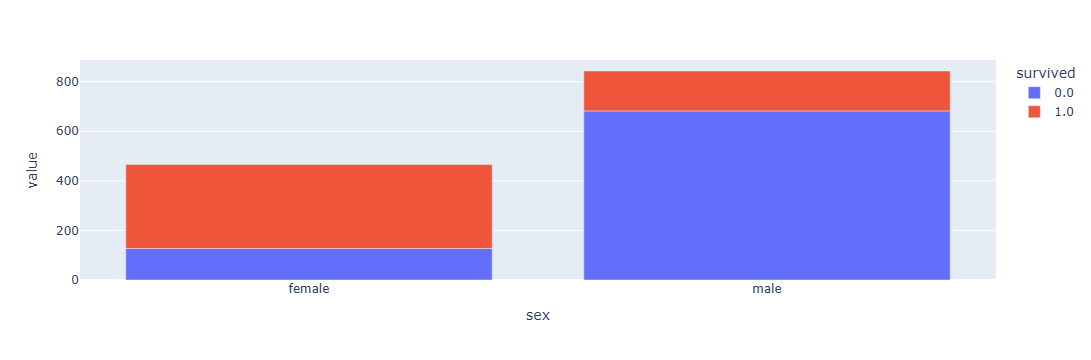

In [34]:

df.groupby(['sex', 'survived']).size().unstack().plot(kind='bar')

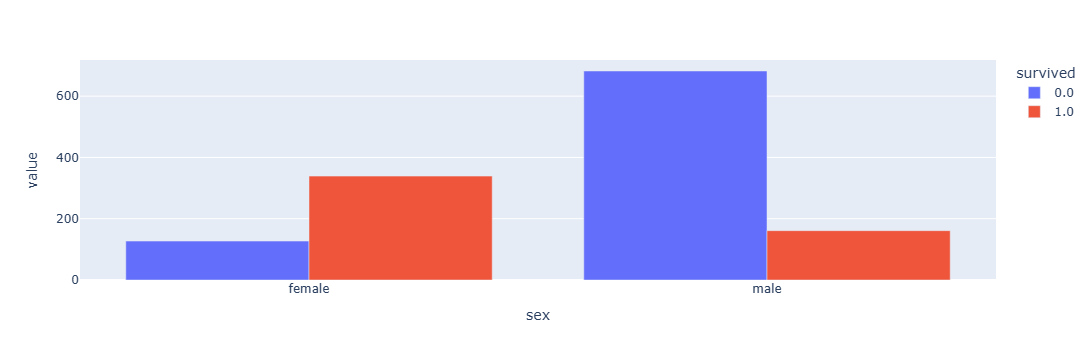

In [35]:

df.groupby(['sex', 'survived']).size().unstack().plot(kind='bar', barmode='group')

### Comment sont représentés les âges par genre ?

Réalisons le résumé statistique par modalité :

In [36]:
# On groupe par sexe, on isole la colonne 'age', et on demande le résumé statistique complet
df.groupby('sex')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
female,388.0,28.687071,14.576995,0.1667,19.0,27.0,38.0,76.0
male,658.0,30.585233,14.280571,0.3333,21.0,28.0,39.0,80.0


### Regardons ça en graphiques !

Avec le boxplot :

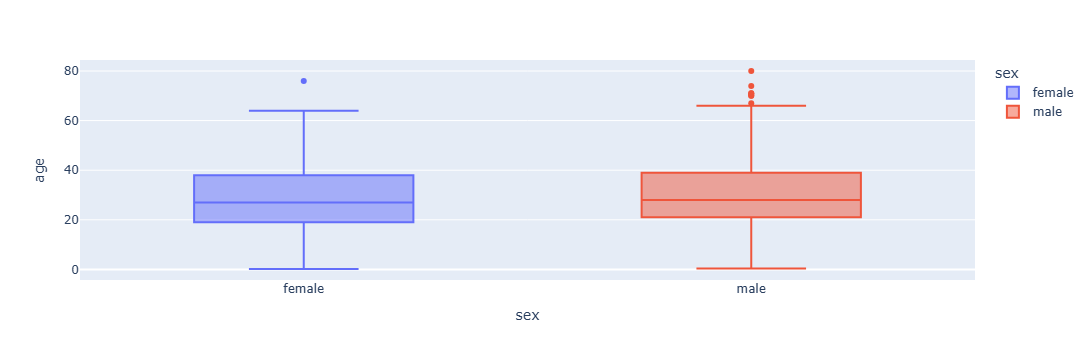

In [37]:
df.plot(kind='box', x='sex', y='age', color='sex')

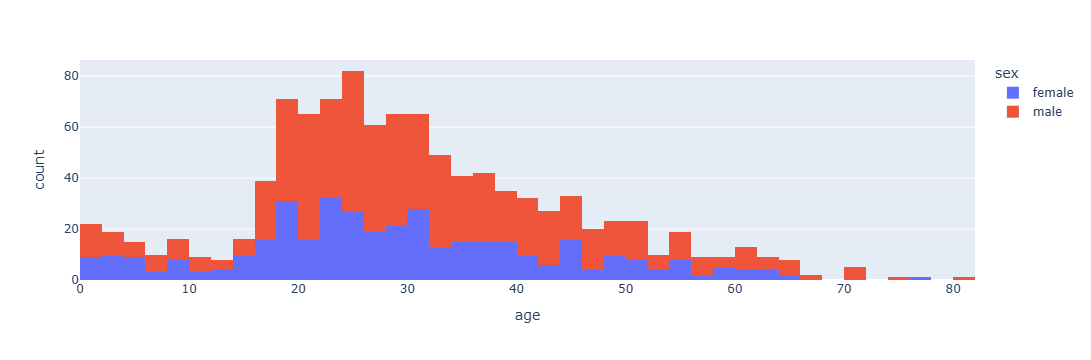

In [38]:
df.plot(kind='hist', x='age', color='sex', bins=30)

Avec la fonction de répartition empirique :

In [39]:

age_femmes = df[df['sex'] == 'female']['age'].dropna()
age_hommes = df[df['sex'] == 'male']['age'].dropna()

ecdf_femmes = ECDF(age_femmes)
ecdf_hommes = ECDF(age_hommes)

df_ecdf = pd.concat([
    pd.DataFrame({'age': ecdf_femmes.x, 'ecdf': ecdf_femmes.y, 'sex': 'female'}),
    pd.DataFrame({'age': ecdf_hommes.x, 'ecdf': ecdf_hommes.y, 'sex': 'male'})
])
df_ecdf

,age,ecdf,sex
0,-inf,0.000000,female
1,0.1667,0.002577,female
2,0.7500,0.005155,female
3,0.7500,0.007732,female
4,0.9167,0.010309,female
...,...,...,...
654,70.5000,0.993921,male
655,71.0000,0.995441,male
656,71.0000,0.996960,male
657,74.0000,0.998480,male


In [40]:
df_clean = df.dropna(subset=['age']).copy()

df_clean['ecdf'] = df_clean.groupby('sex')['age'].rank(method='max', pct=True)

df_clean = df_clean.sort_values('age')

df_clean[['sex','ecdf']].sort_values(by='sex')

,sex,ecdf
763,female,0.002577
589,female,0.561856
24,female,0.561856
369,female,0.561856
521,female,0.561856
...,...,...
880,male,0.533435
746,male,0.533435
715,male,0.533435
1196,male,0.533435


### Peut-on voir un lien entre l'âge et le prix du ticket ?

Regardons ça avec un scatter plot :

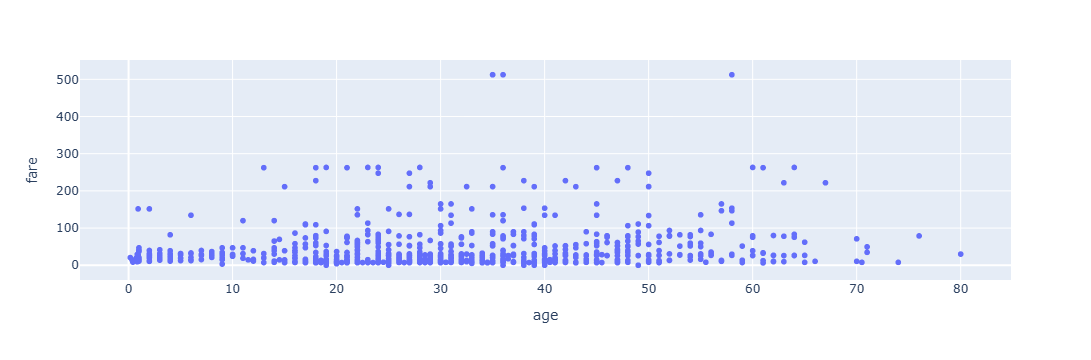

In [41]:
df.plot(kind='scatter', x='age', y='fare')

Regardons le coefficient de corrélation :

In [42]:
# aucune correlation
df[['age','fare']].corr()

,age,fare
age,1.000000,0.178739
fare,0.178739,1.000000


In [43]:
df['age'].corr(df['fare'])

np.float64(0.1787393231464611)

Réalisons la matrice de corrélation en heatmap pour voir ça graphiquement :

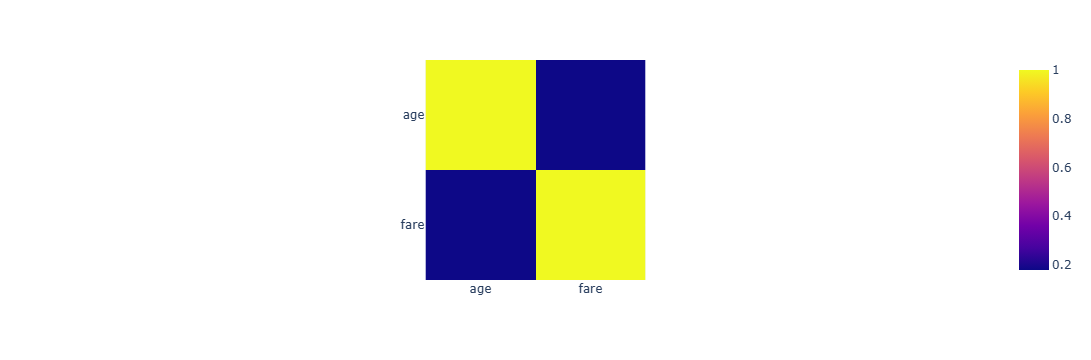

In [44]:
df[['age','fare']].corr().plot(kind='imshow')

Par défaut, la fonction .corr() calcule la <b/>corrélation de Pearson</b>, adaptée lorsque la relation entre les deux variables est linéaire.<br/>
La <b/>corrélation de Spearman</b> quant à elle mesure la relation monotone entre deux variables en se basant sur les rangs des données. Elle est ainsi moins sensible aux outliers et permet de repérer des relations monotones non linéaires.<br/>

🌞 Ressource : https://datascientest.com/correlations-de-pearson-et-de-spearman <br/>

Calculer le coefficient de corrélation de Spearman et comparer le résultat.

In [45]:
df_clean = df.dropna(subset=['age', 'fare'])
df_clean[['age', 'fare']].corr(method='spearman')

,age,fare
age,1.000000,0.192676
fare,0.192676,1.000000


In [46]:
df_clean['age'].corr(df_clean['fare'], method='spearman')

np.float64(0.19267576103868872)

### Semble-t-il y avoir un lien entre la classe sociale et la survie ?

In [47]:
df.groupby('pclass')['survived'].mean() * 100

pclass
1.0    61.919505
2.0    42.960289
3.0    25.528914
Name: survived, dtype: float64

### Continuez d'explorer ce qui vous semble intéressant !

## Tests statistiques

Nous avons pu voir plusieurs informations avec les analyses préliminaires réalisées :
- Les femmes semblent être plus nombreuses à survivre
- Les 1ère classes semblent avoir plus de chance de survivre que les 3ème classe
- ...

### Qu'est-ce qu'un test d'hypothèses ?

Quelques ressources :
- 🌞 https://www.youtube.com/watch?v=0oc49DyA3hU
- 🌞 https://www.youtube.com/watch?v=5koKb5B_YWo

Idée principale : vérifier que les statistiques de l'échantillon sont significatives, c'est à dire que si on reproduit l'expérience, on aurait les mêmes résultats (extrapolation à la population globale).

Autrement dit : à partir des conclusions faites sur un <b/>échantillon</b>, on veut voir si on peut les <b/>généraliser à l'ensemble de la population</b> dont est tiré cet échantillon.

Par exemple si on analyse un échantillon de personnes ayant un cancer en testant deux méthodes pour le soigner et qu'on trouve que la meilleure des solutions est de dormir 12h par nuit, on souhaite que nos statistiques sur cet échantillon soient valables pour toutes les personnes ayant un cancer afin d'être sûre que cette méthode peut être utilisée sur tout le monde.<br/>
<br/>

Il existe différents types de tests, notamment :
- les tests <b/>de conformité à une valeur</b> <i/>(ex : les paquets de farine de ma chaîne de production font-ils bien 500g ?)</i>
- les tests <b/>de comparaison entre des échantillons</b> <i/>(ex : est-ce que les fumeurs ont davantage de risque de cancer que les non fumeurs ?)</i>
- les tests <b/>d'adéquation / de conformité à une loi de probabilité</b> <i/>(ex : est-ce que la distribution des revenus suit une loi normale ?)</i>

Dans chacun des cas, on utilisera une formule spécifique à ce type de test (une fonction différente sur Python).

🌚 Ressource pour plus tard : guide de choix de test statistique - https://hal.science/hal-04292194v1/file/Arbreded%C3%A9cision2023.pdf

Commençons par les tests de comparaison de deux moyennes.

### Les femmes ont-elles significativement plus de chance de survie que les hommes ?

Ou la répartition est-elle due au hasard ?

Peut-être que vous vous demandez : ça se voit avec les effectifs, pourquoi le vérifier statistiquement ?

L'idée des tests d'hypothèses est d'extrapoler ce qu'on voit sur un échantillon à la population globale. Dans notre cas, c'est comme si on voulait vérifier si à l'époque la survie des femmes sur les bâteaux qui rencontrent des icebergs est toujours supérieure à celle des hommes. Pour cela on prend notre échantillon du Titanic en référence.

De la même manière, vous avez peut-être déjà entendu parlé de ça en politique pendant les élections, on peut prendre un village qui aurait les mêmes proportions de femmes, de jeunes, d'artisans,... que la France entière (= échantillon) afin d'extrapoler leurs intentions de vote au niveau national.

**Réalisons notre premier test statistique pas à pas !**

Commençons par réaliser les sous-échantillons d'hommes et de femmes :

In [48]:
sample_femmes = df[df['sex'] == 'female'].sample(n=50, random_state=42)
sample_hommes = df[df['sex'] == 'male'].sample(n=50, random_state=42)


Calculons le taux de survie dans chaque échantillon pour vérifier que notre hypothèse est plausible :

In [49]:
sample_femmes.groupby('survived').size() /50 * 100


survived
0.0    26.0
1.0    74.0
dtype: float64

In [50]:
sample_hommes.groupby('survived').size()/50 * 100


survived
0.0    82.0
1.0    18.0
dtype: float64

Réalisons un premier test afin de voir si les deux proportions sont statistiquement significativement différentes :

Quelques petites informations intéressantes, prenez le temps d'y jeter un coup d'oeil :
- Documentation Python :
    - Test sur une moyenne : https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html#scipy.stats.ttest_1samp
    - Test de comparaison de 2 moyennes : https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html
    - Test sur une proportion : https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html
    - Test de comparaison de 2 proportions : https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportions_ztest.html
    - 🌚 Tous les tests d'hypothèse sur Python : https://docs.scipy.org/doc/scipy/reference/stats.html#hypothesis-tests-and-related-functions <br/>
<br/>
- 🌞 Les étapes de la réalisation d'un test d'hypothèses : https://www.youtube.com/watch?v=I3vnzM1X15g&list=PLWwpP-YNkDjYa9PTCOwJ0A6LNtvbjThsf&index=1

A noter que dans la plupart des cas (notamment quand ce n'est pas précisé), on prendra à une pvaleur à 5%

On pose nos hypothèses H0 et H1 :

In [51]:
# H0 c'est ce qu'on suppose etre vrai / l'hypothese neutre
# contient toujours une egalité (=, =<, >=)
# se qu'on essaie de rejeter
# H0 femme == homme 

#hypothèse concurente
# jamais d'egalité (!=, <, >)
# le contraire de H0
# H1 femme != homme


# les deux hypothèses doivent englober tous les cas possibles

# les ztests c'est pour calculer les taux + big samples >30
# les ttests c'est pour les moyennes + small sample <30
# le chi carrée c'est pour voir si deux variables sont liées ou independantes
# ANOVA comparer les moyennes de plus de 2 groupes en même temps (le t-test ne compare que 2 groupes). Ex: âge moyen selon la classe (1st, 2nd, 3rd) 3 groupes.
# correlation :  tester si deux variables numériques continues sont liées
    # Pearson ==> deux variables continues
    # Spearman ==> variables ordinales OU continues

On réalise notre test :

In [52]:
# count veux dire nb succes (women who survived, men who survived)
count = [sample_femmes['survived'].sum(), sample_hommes['survived'].sum()]
# nobs c'est la taille totale de l'echantillon
nobs = [len(sample_femmes), len(sample_hommes)]
# le test vas comparer count[0]/nobs[0] et count[1]/nobs[1] || two-sided veux dire != & alternative veux dire H1
# alternative = two-sided | larger | smaller ====>>> != | > | <
stat, pval = proportions_ztest(count, nobs, alternative='two-sided')
print(stat, pval)

5.618006477335896 1.931732598569778e-08


Analyse des résultats et conclusion :

In [53]:
# stat == 5.6 ===>> l'ecart entre le taux de survie des femmes et des hommes est de 5.6 fois l'ecart type au dessus du 0 (taux de femmes > taux d'hommes)
# si on inverse dans count la variable stat sera -5.6
# pval = 0.0000000193 <<<< 0.05 ( le seuille qu'on a defini / 5%) ==> H0 est rejetée



On peut refaire le test en vérifiant que la survie des femmes est supérieure à celle des hommes :

In [54]:
# H0: p_femme <= p_homme
# H1: p_femme > p_homme
count = [sample_femmes['survived'].sum(), sample_hommes['survived'].sum()]
nobs = [len(sample_femmes), len(sample_hommes)]
stat, pval = proportions_ztest(count, nobs, alternative='larger')
print(stat, pval)

5.618006477335896 9.65866299284889e-09


Conclusion :

### Focus pvalue + intervalle de confiance

Quelques ressources pour bien comprendre la notion de pvaleur :
- https://fr.wikipedia.org/wiki/Valeur_p
- 🌞 https://www.youtube.com/watch?v=vemZtEM63GY
- 🌞 https://www.youtube.com/watch?v=xVIt51ybvu0
- 🌚 https://www.youtube.com/watch?v=jy9b1HSqtSk

Quelques ressources pour bien comprendre la notion d'intervalle de confiance :
- https://fr.wikipedia.org/wiki/Intervalle_de_confiance
- 🌞 https://www.youtube.com/watch?v=TqOeMYtOc1w
- 🌚 simulateur pour aider à la compréhension : https://im2ag-shiny.univ-grenoble-alpes.fr/fcorset/ICmu/

### COMPETENCE - Les 3ème classe ont-il moins de chance de survie que les 1ère classe ?

In [56]:
sample_1ere = df[df['pclass'] == 1].sample(n=50, random_state=42)
sample_2eme = df[df['pclass'] == 2].sample(n=50, random_state=42)
sample_3eme = df[df['pclass'] == 3].sample(n=50, random_state=42)

count = [sample_3eme['survived'].sum(), sample_1ere['survived'].sum()]
nobs = [len(sample_3eme), len(sample_1ere)]
stat, pval = proportions_ztest(count, nobs, alternative='smaller')
print(stat, pval)

-3.144854510165755 0.0008308472289917536


##### Qu'en est-il des 2nde classe ?

In [57]:
count = [sample_2eme['survived'].sum(), sample_1ere['survived'].sum()]
nobs = [len(sample_2eme), len(sample_1ere)]
stat, pval = proportions_ztest(count, nobs, alternative='smaller')
print(stat, pval)

-1.0050378152592119 0.15743932066820998


In [58]:
count = [sample_2eme['survived'].sum(), sample_3eme['survived'].sum()]
nobs = [len(sample_2eme), len(sample_3eme)]
stat, pval = proportions_ztest(count, nobs, alternative='larger')
print(stat, pval)

2.182178902359924 0.014548165870626094


Conclusion — Survie selon la classe :

1ère vs 3ème classe : avec H0 : p_3ème ≥ p_1ère et H1 : p_3ème < p_1ère, on obtient une p-value de 0.00083, inférieure au seuil α = 5%. On rejette H0. les passagers de 3ème classe ont un taux de survie significativement inférieur à ceux de 1ère classe.

1ère vs 2ème classe : avec H0 : p_2ème ≥ p_1ère et H1 : p_2ème < p_1ère, on obtient une p-value de 0.157, supérieure au seuil α = 5%. On ne rejette pas H0 : on ne peut pas conclure que les passagers de 2ème classe ont un taux de survie significativement inférieur à ceux de 1ère classe.

2ème vs 3ème classe : avec H0 : p_2ème ≤ p_3ème et H1 : p_2ème > p_3ème, on obtient une p-value de 0.0145, inférieure au seuil α = 5%. On rejette H0 : les passagers de 2ème classe ont un taux de survie significativement supérieur à ceux de 3ème classe.

Bilan global : on observe une hiérarchie partielle du taux de survie selon la classe sociale. La 3ème classe est clairement désavantagée par rapport aux deux autres (différence significative face à la 1ère ET face à la 2ème). En revanche, la différence entre 1ère et 2ème classe n'est pas assez marquée pour être statistiquement significative sur cet échantillon — ces deux groupes semblent avoir bénéficié d'un accès comparable au sauvetage, contrairement à la 3ème classe qui apparaît clairement défavorisée.



### Les chances de survie des mineurs étaient-elles supérieures à 50% ?

Identifier le type de test à réaliser parmi ceux cités plus haut.

In [60]:
sample_mineurs = df[df['age'] < 18]
count = sample_mineurs['survived'].sum() 
nobs = len(sample_mineurs)               
stat, pval = proportions_ztest(count, nobs, value=0.5, alternative='larger')
print(stat, pval)

0.6455299732694927 0.25929190044187567


In [61]:
sample_mineurs['survived'].mean()

np.float64(0.525974025974026)

### Le genre et la survie sont-elles deux variables indépendantes ?

Une autre manière d'aborder la question de la survie selon le genre est de réaliser un test d'indépendance du Khi-deux.<br/>
<br/>
🌞 Ressources :
- Pour expliquer ce test : https://datatab.fr/tutorial/chi-square-test
- Test du Khi-deux d'indépendance sur Python : https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html

In [62]:
# Tableau de contingence avec crosstab
table = pd.crosstab(df['sex'], df['survived'])
table

survived,0.0,1.0
sex,,
female,127,339
male,682,161


In [66]:
# Test du Khi-deux
from scipy.stats import chi2_contingency
stat, pval, dof, expected = chi2_contingency(table)
print(stat, pval)
print(dof)
print(expected)

363.6179084388249 4.589924936952945e-81
1
[[288.00152788 177.99847212]
 [520.99847212 322.00152788]]


In [ ]:
# testet l'independance de deux variables
# stat =  l'écart total entre les effectifs observés et les effectifs attendus 
# pval = meme logique que dans les ztests
# dof =  degree of freedom 
# expected = un tableau (ce qu'on aurait dû observer si les deux variables étaient parfaitement indépendantes.)

### COMPETENCE - Y a-t-il un lien entre le genre et la classe ?

In [67]:
table2 = pd.crosstab(df['sex'], df['pclass'])
stat2, pval2, dof2, expected2 = chi2_contingency(table2)
print(stat2, pval2)
print(dof2) # dof = (2-1)×(3-1) = 2 ==> sex => 2categories / pclass => 3 categories
print(expected2)

20.378781205085588 3.7566772719164024e-05
2
[[114.98701299  98.61115355 252.40183346]
 [208.01298701 178.38884645 456.59816654]]


### Continuez d'explorer ce qui vous semble intéressant !

# Petite pause avec le paradoxe de Simpson

🌞 https://www.youtube.com/watch?v=vs_Zzf_vL2I

# Sujet 2 : Enquête sur le bonheur

Des étudiants en Master 1 Sciences Des Données à l'Université Grenoble Alpes ont réalisée une étude sur le bonheur lors d'un de leurs projets tutorés en 2020

Importez les données :

In [69]:
df = pd.read_csv("Data/enquete_sur_le_bonheur.csv", sep=';')
df

,Timestamp,Quel est votre sexe ?,Quel est votre âge ? (Ex : 30 pour 30 ans),Dans quel département habitez-vous ? (Ex : 38 pour l'Isère / 0 si hors France),Etes vous heureux ?,Accordez-vous de l'importance à ... ? (Cochez si oui),Vous épanouissez-vous dans votre travail ?,Accordez-vous de l'importance à l'argent ?,Etes-vous plutôt ville ou nature ?,Accordez-vous de l'importance à votre temps personnel ?,Accordez-vous de l'importance aux activités sportives ?,Accordez-vous de l'importance aux activités créatives ?,Prenez-vous soin de votre santé ?,Accordez-vous de l'importance à votre développement personnel ?,Quel était votre rêve d'enfant ?,"Si vous fermez les yeux et imaginez un endroit où vous vous sentez bien, comment le décririez-vous ?",Que faites vous qui vous rende heureux pendant votre temps personnel ?,Qu'est ce qui vous rend heureux au quotidien ?,Quel est votre but dans la vie ?,Qu'est-ce qu'être heureux selon vous ?
0,9/29/2020 18:16:11,Femme,24,38,3,"Votre famille, Vos amis, Vos relations amoureu...",3.0,2,5,5,2,5,2,5,Je rêvais d'être artiste et d'avoir plein d'an...,"C'est une vaste plaine, avec énormément de fle...","Des créations artistiques (bijoux, dessins, br...",Savoir que les personnes qui m'entourent vont ...,"Être heureux, trouver le bonheur.","Être dans un bon état d'esprit, sans angoissé ..."
1,9/29/2020 18:19:18,Femme,22,38,4,"Votre famille, Vos amis, Vos relations amoureu...",3.0,5,4,5,2,1,3,2,Je n'avais pas de rêve quand j'étais enfant.,"Un endroit ni calme, ni bruyant, confortableme...","Manger, ou dormir.","Les petits plaisirs de la vie, la colloc, la f...","Je n'en ai pas spécialement, avoir les bonnes ...","Pour moi, c'est être satisfait de soi-même, de..."
2,9/29/2020 18:26:09,Femme,24,38,4,"Votre famille, Vos amis, Vos relations amoureu...",5.0,3,4,2,4,5,5,2,Je revaiq de devenir fermière et d'élever des ...,Une table de Noël avec toute ma famille et les...,Je prend soin de moi,Etre avec les gens que j'aime,Fonder une famille plein d'amour,"Etre bien dans sa peau, dans sa vie. Et être e..."
3,9/29/2020 18:28:35,Femme,30,1,4,"Votre famille, Vos amis, Vos relations amoureuses",4.0,5,4,3,2,4,4,2,Avoir des enfants,"Dans la nature, surtout près de l'eau",Prendre du temps pour moi,"Ma maison, mes chats, mon chéri",Être pleinement épanouie entre ma vie perso (u...,"Accomplir son objectif de vie, faire ce qui no..."
4,9/29/2020 18:30:32,Homme,33,77,4,"Votre famille, Vos amis, Vos relations amoureuses",3.0,5,1,5,3,3,3,3,devenir footballeur,Avec ma famille dans un parc,Me reposer,Manger et se reposer,Que ma famille ne manque de rien,Avoir la paix intérieure
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
418,10/12/2020 10:02:00,Femme,29,38,4,"Votre famille, Vos amis, Vos relations amoureu...",4.0,1,5,5,4,4,4,4,Je ne me rappelle plus si j'en avais un,Assise dans la nature devant un beau ciel colo...,"Je partage du temps avec mes amis, ma famille,...",Idem + partager avec mes adorables étudiants,Être heureuse,Profiter des petits moments partagés avec mes ...
419,10/12/2020 13:21:43,Homme,63,974,4,"Votre famille, Vos amis, Vos relations amoureuses",4.0,4,3,4,5,2,4,4,Devenir vétérinaire,"Un endroit avec de la verdure, de la chaleur, ...",Des câlins,"Le soleil, la vue de l'océan, les oiseaux qui ...",être heureux et sans pb d'argent,"Avant toute chose, une santé de fer. Puis un s..."
420,10/12/2020 19:25:39,Femme,21,69,3,"Votre famille, Vos amis, Vos relations amoureu...",5.0,5,4,4,3,4,5,5,Etre une chanteuse et remplir des salles de sp...,"Je me vois sur une plage de galets, avec le br...","Je fais du sport, de la musique, je chante, je...",Développer un peu plus chaque jour des relatio...,"Avoir un métier stimulant, qui me permette de ...",Pouvoir manger sans grossir !
421,10/12/2020 21:53:41,Femme,22,69,4,"Votre famille, Vos amis, Vos relations amoureu...",4.0,4,3,4,5,1,3,3,Devenir chanteuse,"Calme, au bord de la mer et entourée des perso...","Du sport, profiter de ma fam

Regardez globalement ce qu'il y a dedans :

In [70]:
df.head(1).T

,0
Timestamp,9/29/2020 18:16:11
Quel est votre sexe ?,Femme
Quel est votre âge ? (Ex : 30 pour 30 ans),24
Dans quel département habitez-vous ? (Ex : 38 pour l'Isère / 0 si hors France),38
Etes vous heureux ?,3
Accordez-vous de l'importance à ... ? (Cochez si oui),"Votre famille, Vos amis, Vos relations amoureu..."
Vous épanouissez-vous dans votre travail ?,3.0
Accordez-vous de l'importance à l'argent ?,2
Etes-vous plutôt ville ou nature ?,5
Accordez-vous de l'importance à votre temps personnel ?,5


In [71]:
df.columns

Index(['Timestamp', 'Quel est votre sexe ?',
       'Quel est votre âge ? (Ex : 30 pour 30 ans)',
       'Dans quel département habitez-vous ? (Ex : 38 pour l'Isère / 0 si hors France)',
       'Etes vous heureux ?',
       'Accordez-vous de l'importance à ... ? (Cochez si oui)',
       'Vous épanouissez-vous dans votre travail ?',
       'Accordez-vous de l'importance à l'argent ?',
       'Etes-vous plutôt ville ou nature ?',
       'Accordez-vous de l'importance à votre temps personnel ?',
       'Accordez-vous de l'importance aux activités sportives ?',
       'Accordez-vous de l'importance aux activités créatives ?',
       'Prenez-vous soin de votre santé ?',
       'Accordez-vous de l'importance à votre développement personnel ?',
       'Quel était votre rêve d'enfant ?',
       'Si vous fermez les yeux et imaginez un endroit où vous vous sentez bien, comment le décririez-vous ?',
       'Que faites vous qui vous rende heureux pendant votre temps personnel ?',
       'Qu'est ce

In [74]:
df = df.rename(columns={
    'Quel est votre sexe ?': 'sexe',
    'Quel est votre âge ? (Ex : 30 pour 30 ans)': 'age',
    "Dans quel département habitez-vous ? (Ex : 38 pour l'Isère / 0 si hors France)": 'departement',
    'Etes vous heureux ?': 'bonheur',
    "Accordez-vous de l'importance à ... ? (Cochez si oui)": 'importance_categories',
    'Vous épanouissez-vous dans votre travail ?': 'epanouissement_travail',
    "Accordez-vous de l'importance à l'argent ?": 'importance_argent',
    'Etes-vous plutôt ville ou nature ?': 'ville_nature',
    "Accordez-vous de l'importance à votre temps personnel ?": 'importance_temps_perso',
    "Accordez-vous de l'importance aux activités sportives ?": 'importance_sport',
    "Accordez-vous de l'importance aux activités créatives ?": 'importance_creativite',
    'Prenez-vous soin de votre santé ?': 'soin_sante',
    "Accordez-vous de l'importance à votre développement personnel ?": 'importance_dev_perso',
    "Quel était votre rêve d'enfant ?": 'reve_enfant',
    'Si vous fermez les yeux et imaginez un endroit où vous vous sentez bien, comment le décririez-vous ?': 'endroit_ideal',
    'Que faites vous qui vous rende heureux pendant votre temps personnel ?': 'activite_heureuse',
    "Qu'est ce qui vous rend heureux au quotidien ?": 'bonheur_quotidien',
    'Quel est votre but dans la vie ?': 'but_vie',
    "Qu'est-ce qu'être heureux selon vous ?": 'definition_bonheur',
})

In [75]:
df.columns

Index(['Timestamp', 'sexe', 'age', 'departement', 'bonheur',
       'importance_categories', 'epanouissement_travail', 'importance_argent',
       'ville_nature', 'importance_temps_perso', 'importance_sport',
       'importance_creativite', 'soin_sante', 'importance_dev_perso',
       'reve_enfant', 'endroit_ideal', 'activite_heureuse',
       'bonheur_quotidien', 'but_vie', 'definition_bonheur'],
      dtype='object')

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423 entries, 0 to 422
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Timestamp               423 non-null    object 
 1   sexe                    423 non-null    object 
 2   age                     423 non-null    int64  
 3   departement             423 non-null    int64  
 4   bonheur                 423 non-null    int64  
 5   importance_categories   423 non-null    object 
 6   epanouissement_travail  414 non-null    float64
 7   importance_argent       423 non-null    int64  
 8   ville_nature            423 non-null    int64  
 9   importance_temps_perso  423 non-null    int64  
 10  importance_sport        423 non-null    int64  
 11  importance_creativite   423 non-null    int64  
 12  soin_sante              423 non-null    int64  
 13  importance_dev_perso    423 non-null    int64  
 14  reve_enfant             422 non-null    ob

In [78]:
df.describe()

,age,departement,bonheur,epanouissement_travail,importance_argent,ville_nature,importance_temps_perso,importance_sport,importance_creativite,soin_sante,importance_dev_perso
count,423.000000,423.000000,423.000000,414.000000,423.000000,423.000000,423.000000,423.000000,423.000000,423.000000,423.000000
mean,34.621749,241.368794,3.926714,3.545894,3.340426,3.692671,4.172577,3.496454,3.063830,3.607565,3.673759
std,13.034722,3814.976911,0.832868,1.074273,0.974775,1.118614,0.913825,1.244652,1.278029,0.952492,1.065373
min,9.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,24.000000,34.000000,3.000000,3.000000,3.000000,3.000000,4.000000,3.000000,2.000000,3.000000,3.000000
50%,31.000000,38.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,3.000000,4.000000,4.000000
75%,43.500000,74.000000,4.000000,4.000000,4.000000,5.000000,5.000000,5.000000,4.000000,4.000000,5.000000
max,99.000000,78500.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [79]:
df.dtypes


Timestamp                  object
sexe                       object
age                         int64
departement                 int64
bonheur                     int64
importance_categories      object
epanouissement_travail    float64
importance_argent           int64
ville_nature                int64
importance_temps_perso      int64
importance_sport            int64
importance_creativite       int64
soin_sante                  int64
importance_dev_perso        int64
reve_enfant                object
endroit_ideal              object
activite_heureuse          object
bonheur_quotidien          object
but_vie                    object
definition_bonheur         object
dtype: object

In [80]:
df.head(1).T

,0
Timestamp,9/29/2020 18:16:11
sexe,Femme
age,24
departement,38
bonheur,3
importance_categories,"Votre famille, Vos amis, Vos relations amoureu..."
epanouissement_travail,3.0
importance_argent,2
ville_nature,5
importance_temps_perso,5


C:\Users\Dell\AppData\Local\Temp\ipykernel_86896\1346421986.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



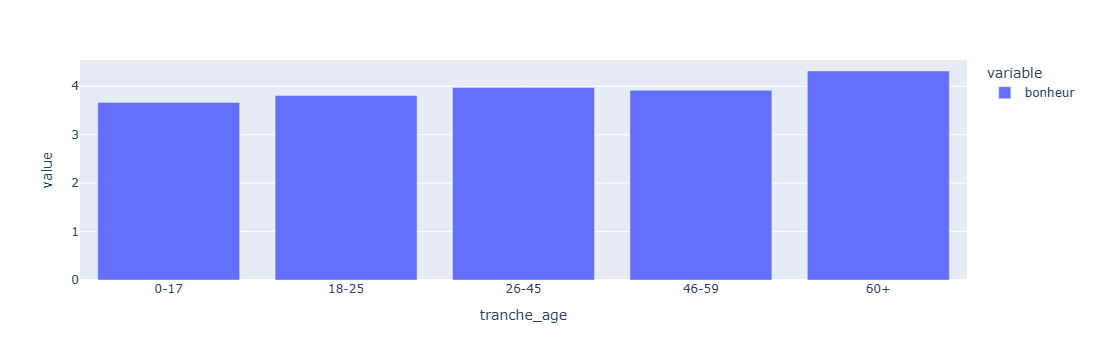

In [105]:
# bonheur par tranche d'age
df['tranche_age'] = pd.cut(df['age'], bins=[0, 17, 25, 45, 59, 150],labels=['0-17', '18-25', '26-45', '46-59', '60+'])

bonheur_par_tranche = df.groupby('tranche_age')['bonheur'].mean()

bonheur_par_tranche.index = bonheur_par_tranche.index.astype(str)

bonheur_par_tranche.plot(kind='bar')

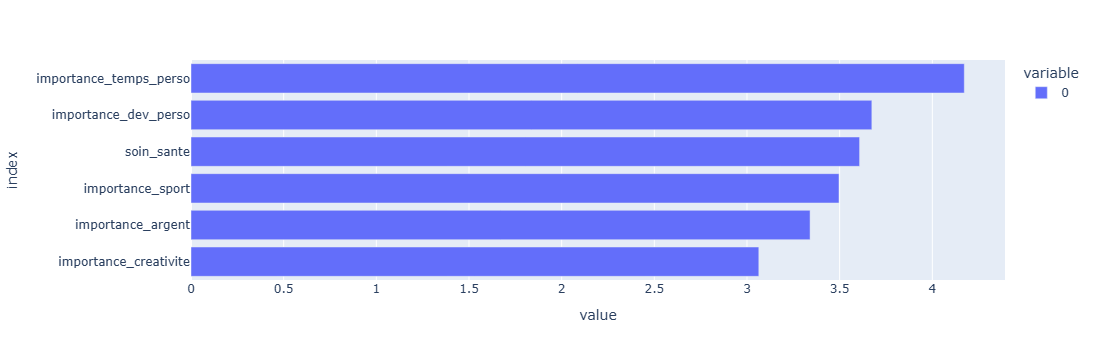

In [96]:
# classement des priorités
priorites = df[['importance_argent','importance_temps_perso','importance_sport',
                 'importance_creativite','soin_sante','importance_dev_perso']].mean().sort_values()

priorites.plot(kind='barh')


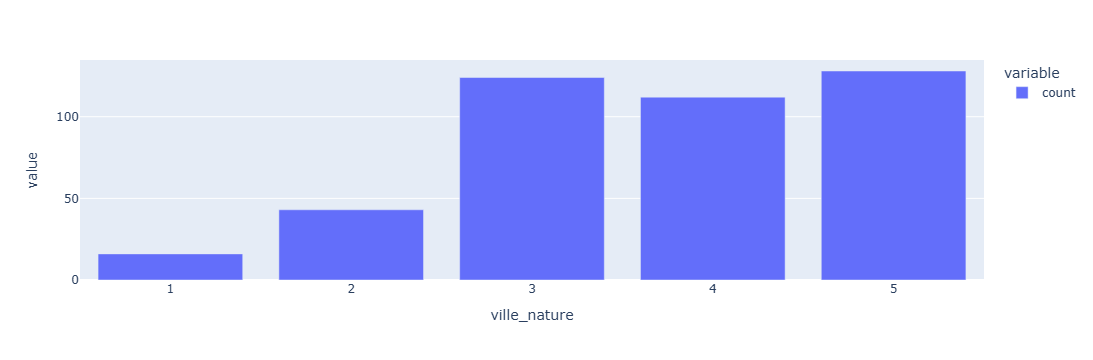

In [100]:
df['ville_nature'].value_counts().plot(kind='bar')


## COMPETENCE - Réaliser une mini infographie d'une demie page avec au moins 5 informations intéressantes découvertes (dont au moins 2 tests d'hypothèses) dans ce jeu de données

In [104]:
# bonheur femme vs homme
df['est_heureux'] = df['bonheur'] >= 4
sample_femmes = df[df['sexe'] == 'Femme']
sample_hommes = df[df['sexe'] == 'Homme']

count = [sample_femmes['est_heureux'].sum(), sample_hommes['est_heureux'].sum()]
nobs = [len(sample_femmes), len(sample_hommes)]
stat, pval = proportions_ztest(count, nobs, alternative='two-sided')
print(stat, pval) # pas de difference entre les femmes et les hommes

0.28498623362885134 0.7756546887709608


In [103]:
#H0: p_epanoui <= p_pas_epanoui   (l'épanouissement au travail n'augmente pas le taux de bonheur)
#H1: p_epanoui > p_pas_epanoui    (les gens épanouis au travail sont plus heureux)
sample_epanoui = df[df['epanouissement_travail'] >= 4]
sample_pas_epanoui = df[(df['epanouissement_travail'] < 4) & (df['epanouissement_travail'].notna())]

count = [sample_epanoui['est_heureux'].sum(), sample_pas_epanoui['est_heureux'].sum()]
nobs = [len(sample_epanoui), len(sample_pas_epanoui)]
stat, pval = proportions_ztest(count, nobs, alternative='larger')
print(stat, pval)
# On conclut que le taux de bonheur est significativement supérieur chez les personnes épanouies dans leur travail
# par rapport à celles qui ne le sont pas. 

6.371727921399749 9.3455129212301e-11


A vous d'analyser les données avec tout ce que vous avez appris !

#  Sujet 3 (bonus) : Application mobile : jeu Cookie Cats

Les données sont issues de Kaggle : https://www.kaggle.com/datasets/yufengsui/mobile-games-ab-testing

Les tests statistiques sont également utilisés dans le test de nouvelles fonctionnalités (application, site web,...), afin de voir si mettre un bouton en turquoise attire plus qu'un bouton en fushia par exemple.

Ressources :
- https://fr.wikipedia.org/wiki/Test_A/B
- 🌞 https://www.youtube.com/watch?v=BmNBxAhatYI

Importez les données :

Regardez globalement ce qu'il y a dedans :

Nous avons ici plusieurs informations :
- userid : identifiant de l'utilisateur
- version : les deux versions de l'application à comparer
- les indicateurs de performance de l'application :
    - sum_gamerounds : le nombre de tours de jeu joués par le joueur au cours des 14 premiers jours suivant l'installation
    - retention_1 : est-ce que le joueur est revenu et a joué 1 jour après l'installation ?
    - retention_7 : est-ce que le joueur est revenu et a joué 7 jours après l'installation ?

L'idée ici va être de regarder quelle version de l'application permet une meilleure performance de cette dernière en moyenne.

Commençons par créer les deux groupes à comparer :

## En terme de nombre de tours joués par le joueur au cours des 14 premiers jours, quelle version est la meilleure ?

## Par rapport aux joueurs qui reviennent 1 jour après l'installation, quelle version est la meilleure ?

## Par rapport aux joueurs qui reviennent 7 jours après l'installation, quelle version est la meilleure ?

## Quelle version devrait choisir l'éditeur selon vous ?

# BONUS

## Création de nouvelles variables afin d'étoffer l'analyse

Regardez la distribution des âges ou basez vous sur vos propres critères afin de définir des classes d'âge. </br>
Pouvez-vous déceler des informations intéressantes sur les jeunes, les vieux ?

## Nettoyage des données aberrantes

Certaines données extrêmes semblent bizarres, peut-être fausses, il pourrait être intéressant de les enlever dans nos analyses

## Analyse des questions ouvertes

Comment peut-on analyser les questions ouvertes ?

## Tests sur la variance

Il est également possible de réaliser des tests sur la variance. </br>
Si ça vous intéresse n'hésitez pas à creuser le sujet ;)